# CART Implementation Using a Student Performance Dataset

**Objective:** Implement a Classification and Regression Tree (CART) for a classification problem using a Student Performance dataset.

In this notebook, the target is **Result** (`Pass` / `Fail`). We first calculate Gini impurity and compare binary splits manually, then train a CART decision tree using Scikit-learn.

## 1. Import required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)

## 2. Create the Student Performance dataset

This is a small illustrative dataset created for this exercise. It is different from the Play Tennis dataset.

In [2]:
data = {
    "Study_Hours": [1,2,3,1,4,5,2,6,3,7,1,4,5,2,6,3,7,8,2,5,4,9,1,6,8,3,7,4,9,2,5,8,6,1,7,3,9,4,8,2],
    "Attendance": [55,60,65,50,72,80,58,88,68,92,52,75,82,62,90,66,95,96,57,84,78,98,54,89,97,64,93,76,99,59,85,94,87,53,91,67,98,79,96,61],
    "Assignments": ["Low","Low","Medium","Low","Medium","High","Low","High","Medium","High","Low","Medium","High","Low","High","Medium","High","High","Low","High","Medium","High","Low","High","High","Medium","High","Medium","High","Low","High","High","High","Low","High","Medium","High","Medium","High","Low"],
    "Internet_Access": ["No","Yes","Yes","No","Yes","Yes","No","Yes","Yes","Yes","No","Yes","Yes","Yes","Yes","No","Yes","Yes","No","Yes","Yes","Yes","No","Yes","Yes","Yes","Yes","No","Yes","No","Yes","Yes","Yes","No","Yes","Yes","Yes","Yes","Yes","No"],
    "Result": ["Fail","Fail","Fail","Fail","Pass","Pass","Fail","Pass","Fail","Pass","Fail","Pass","Pass","Fail","Pass","Fail","Pass","Pass","Fail","Pass","Pass","Pass","Fail","Pass","Pass","Fail","Pass","Pass","Pass","Fail","Pass","Pass","Pass","Fail","Pass","Fail","Pass","Pass","Pass","Fail"]
}
df = pd.DataFrame(data)
df.head()

,Study_Hours,Attendance,Assignments,Internet_Access,Result
0,1,55,Low,No,Fail
1,2,60,Low,Yes,Fail
2,3,65,Medium,Yes,Fail
3,1,50,Low,No,Fail
4,4,72,Medium,Yes,Pass


## 3. Explore the dataset

In [3]:
print("Dataset shape:", df.shape)
print("\\nDataset information:")
df.info()
print("\\nMissing values:")
print(df.isnull().sum())
print("\\nTarget distribution:")
print(df["Result"].value_counts())

Dataset shape: (40, 5)
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Study_Hours      40 non-null     int64 
 1   Attendance       40 non-null     int64 
 2   Assignments      40 non-null     object
 3   Internet_Access  40 non-null     object
 4   Result           40 non-null     object
dtypes: int64(2), object(3)
memory usage: 1.7+ KB
\nMissing values:
Study_Hours        0
Attendance         0
Assignments        0
Internet_Access    0
Result             0
dtype: int64
\nTarget distribution:
Result
Pass    24
Fail    16
Name: count, dtype: int64


In [4]:
df.describe(include="all")

,Study_Hours,Attendance,Assignments,Internet_Access,Result
count,40.000000,40.000000,40,40,40
unique,NaN,NaN,3,2,2
top,NaN,NaN,High,Yes,Pass
freq,NaN,NaN,19,29,24
mean,4.575000,76.625000,NaN,NaN,NaN
std,2.560924,15.933657,NaN,NaN,NaN
min,1.000000,50.000000,NaN,NaN,NaN
25%,2.000000,61.750000,NaN,NaN,NaN
50%,4.000000,78.500000,NaN,NaN,NaN
75%,7.000000,91.250000,NaN,NaN,NaN


## 3A. Visualize the dataset

These exploratory graphs help us understand the student data before building the CART model.

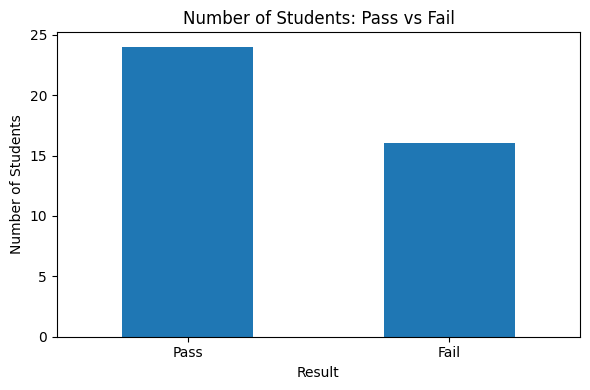

In [5]:
# Graph 1: Number of students in each result class
plt.figure(figsize=(6, 4))
df["Result"].value_counts().reindex(["Pass", "Fail"]).plot(kind="bar")
plt.title("Number of Students: Pass vs Fail")
plt.xlabel("Result")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

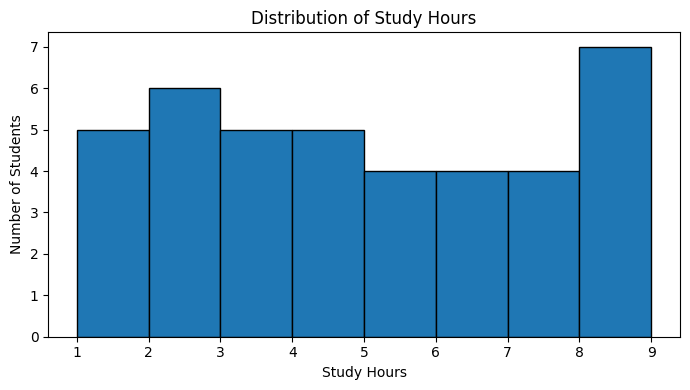

In [6]:
# Graph 2: Distribution of study hours
plt.figure(figsize=(7, 4))
plt.hist(df["Study_Hours"], bins=8, edgecolor="black")
plt.title("Distribution of Study Hours")
plt.xlabel("Study Hours")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

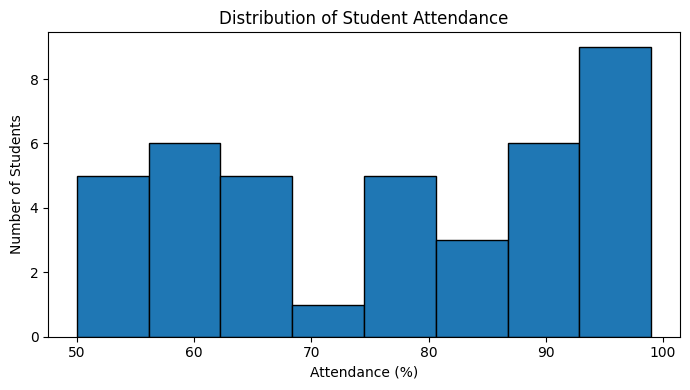

In [7]:
# Graph 3: Distribution of attendance
plt.figure(figsize=(7, 4))
plt.hist(df["Attendance"], bins=8, edgecolor="black")
plt.title("Distribution of Student Attendance")
plt.xlabel("Attendance (%)")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

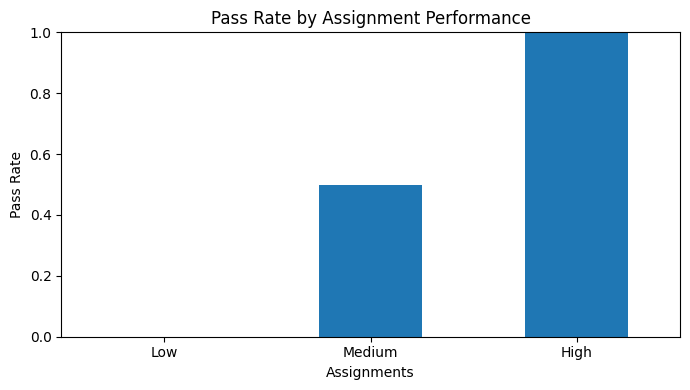

In [8]:
# Graph 4: Pass rate by assignment performance
pass_rate_assignments = (
    df.assign(Passed=(df["Result"] == "Pass").astype(int))
      .groupby("Assignments")["Passed"].mean()
      .reindex(["Low", "Medium", "High"])
)
plt.figure(figsize=(7, 4))
pass_rate_assignments.plot(kind="bar")
plt.title("Pass Rate by Assignment Performance")
plt.xlabel("Assignments")
plt.ylabel("Pass Rate")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

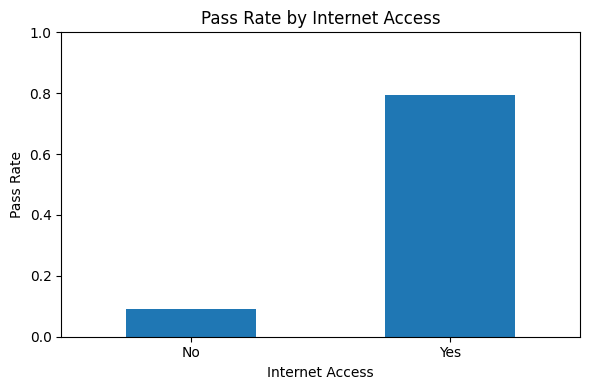

In [9]:
# Graph 5: Pass rate by internet access
pass_rate_internet = (
    df.assign(Passed=(df["Result"] == "Pass").astype(int))
      .groupby("Internet_Access")["Passed"].mean()
      .reindex(["No", "Yes"])
)
plt.figure(figsize=(6, 4))
pass_rate_internet.plot(kind="bar")
plt.title("Pass Rate by Internet Access")
plt.xlabel("Internet Access")
plt.ylabel("Pass Rate")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

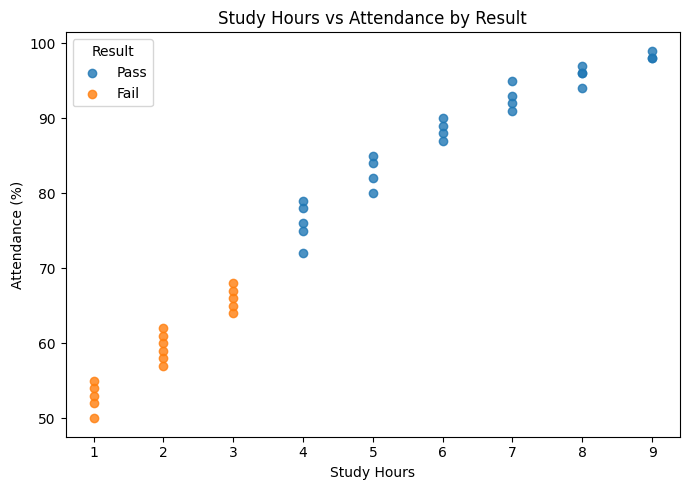

In [10]:
# Graph 6: Study hours vs attendance, grouped by result
plt.figure(figsize=(7, 5))
for result in ["Pass", "Fail"]:
    subset = df[df["Result"] == result]
    plt.scatter(
        subset["Study_Hours"], subset["Attendance"],
        label=result, alpha=0.8
    )
plt.title("Study Hours vs Attendance by Result")
plt.xlabel("Study Hours")
plt.ylabel("Attendance (%)")
plt.legend(title="Result")
plt.tight_layout()
plt.show()

## 4. Separate features and target

In [11]:
X = df.drop("Result", axis=1)
y = df["Result"]

print("Features:")
display(X.head())
print("Target:")
display(y.head())

Features:


,Study_Hours,Attendance,Assignments,Internet_Access
0,1,55,Low,No
1,2,60,Low,Yes
2,3,65,Medium,Yes
3,1,50,Low,No
4,4,72,Medium,Yes


Target:


0    Fail
1    Fail
2    Fail
3    Fail
4    Pass
Name: Result, dtype: object

## 5. Calculate Gini impurity

Gini impurity measures how mixed the classes are in a node. A node containing only one class has Gini impurity 0.

In [12]:
def gini_impurity(labels):
    proportions = labels.value_counts(normalize=True)
    return 1 - np.sum(proportions ** 2)

parent_gini = gini_impurity(y)
print("Parent Gini Impurity:", round(parent_gini, 4))

Parent Gini Impurity: 0.48


## 6. Calculate weighted child Gini and Gini reduction

CART makes **binary splits**. For categorical columns, the code below tests one category against all remaining categories. For numeric columns, it tests candidate threshold values.

In [13]:
def weighted_child_gini(left_labels, right_labels):
    total = len(left_labels) + len(right_labels)
    return (
        (len(left_labels) / total) * gini_impurity(left_labels)
        + (len(right_labels) / total) * gini_impurity(right_labels)
    )

def evaluate_binary_split(feature_values, target, split_description):
    left_mask = np.asarray(feature_values)
    left_labels = target.iloc[np.where(left_mask)[0]]
    right_labels = target.iloc[np.where(~left_mask)[0]]

    if len(left_labels) == 0 or len(right_labels) == 0:
        return None

    child_gini = weighted_child_gini(left_labels, right_labels)
    reduction = gini_impurity(target) - child_gini

    return {
        "Split": split_description,
        "Weighted Child Gini": child_gini,
        "Gini Reduction": reduction
    }

## 7. Find the best manual binary split

In [14]:
split_results = []

for column in X.columns:
    values = X[column]

    if pd.api.types.is_numeric_dtype(values):
        unique_values = np.sort(values.unique())
        thresholds = (unique_values[:-1] + unique_values[1:]) / 2

        for threshold in thresholds:
            mask = (values <= threshold).to_numpy()
            result = evaluate_binary_split(
                mask, y, f"{column} <= {threshold:.2f}"
            )
            if result:
                split_results.append(result)
    else:
        for category in values.unique():
            mask = (values == category).to_numpy()
            result = evaluate_binary_split(
                mask, y, f"{column} == {category}"
            )
            if result:
                split_results.append(result)

split_table = pd.DataFrame(split_results).sort_values(
    "Gini Reduction", ascending=False
).reset_index(drop=True)

display(split_table.head(10))
print("Best split:", split_table.iloc[0]["Split"])
print("Best Gini reduction:", round(split_table.iloc[0]["Gini Reduction"], 4))

,Split,Weighted Child Gini,Gini Reduction
0,Study_Hours <= 3.50,0.000000,0.480000
1,Attendance <= 70.00,0.000000,0.480000
2,Attendance <= 73.50,0.047059,0.432941
3,Attendance <= 67.50,0.048000,0.432000
4,Attendance <= 75.50,0.088889,0.391111
5,Attendance <= 66.50,0.092308,0.387692
6,Attendance <= 77.00,0.126316,0.353684
7,Attendance <= 65.50,0.133333,0.346667
8,Attendance <= 78.50,0.160000,0.320000
9,Attendance <= 64.50,0.171429,0.308571


Best split: Study_Hours <= 3.50
Best Gini reduction: 0.48


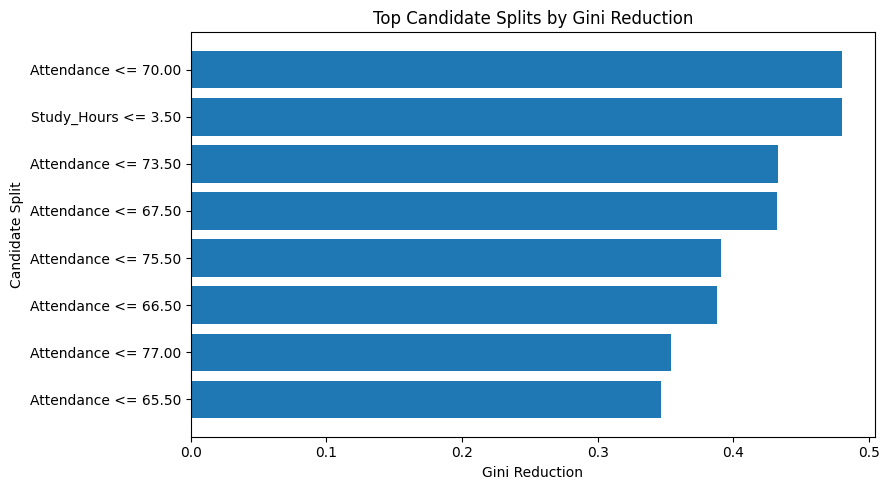

In [15]:
# Graph 7: Gini reduction for the top candidate splits
top_splits = split_table.head(8).sort_values("Gini Reduction")
plt.figure(figsize=(9, 5))
plt.barh(top_splits["Split"], top_splits["Gini Reduction"])
plt.title("Top Candidate Splits by Gini Reduction")
plt.xlabel("Gini Reduction")
plt.ylabel("Candidate Split")
plt.tight_layout()
plt.show()

## 8. Prepare training and testing data

We use an 80:20 split and stratify by the target so that both sets retain a similar class distribution.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)
print("\\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(2))
print("\\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(2))

Training set shape: (32, 4)
Testing set shape: (8, 4)
\nTraining target distribution:
Result
Pass    0.59
Fail    0.41
Name: proportion, dtype: float64
\nTesting target distribution:
Result
Pass    0.62
Fail    0.38
Name: proportion, dtype: float64


## 9. Preprocess the features

One-hot encoding converts categorical columns into numeric indicator columns. The transformer is fitted inside the pipeline using only the training data.

In [17]:
numeric_features = ["Study_Hours", "Attendance"]
categorical_features = ["Assignments", "Internet_Access"]

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numeric", "passthrough", numeric_features)
    ]
)

## 10. Build and train the CART model

`criterion="gini"` makes the decision tree use Gini impurity to select splits.

In [18]:
cart_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=4,
        random_state=42
    ))
])

cart_pipeline.fit(X_train, y_train)
print("CART model training completed successfully.")

CART model training completed successfully.


## 11. Make predictions

In [19]:
y_pred = cart_pipeline.predict(X_test)

results = pd.DataFrame({
    "Actual Result": y_test.values,
    "Predicted Result": y_pred
})
display(results)

,Actual Result,Predicted Result
0,Fail,Fail
1,Fail,Fail
2,Pass,Pass
3,Pass,Pass
4,Pass,Pass
5,Pass,Pass
6,Fail,Fail
7,Pass,Pass


## 12. Evaluate the model

In [20]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", round(accuracy * 100, 2), "%")

print("\\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 100.0 %
\nClassification Report:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         3
        Pass       1.00      1.00      1.00         5

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8



## 13. Confusion matrix

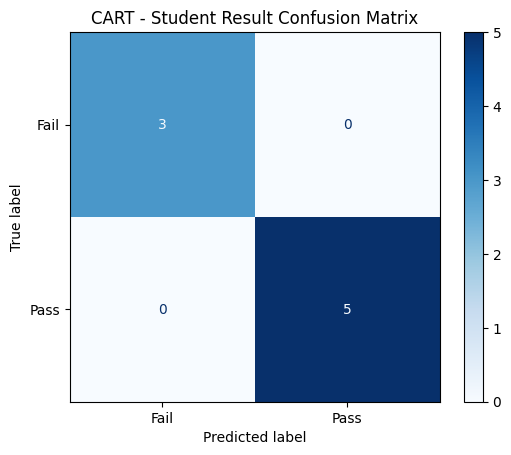

In [21]:
cm = confusion_matrix(y_test, y_pred, labels=["Fail", "Pass"])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fail", "Pass"]
)
disp.plot(cmap="Blues")
plt.title("CART - Student Result Confusion Matrix")
plt.show()

## 14. Visualize the decision tree

In [ ]:
fitted_preprocessor = cart_pipeline.named_steps["preprocessor"]
feature_names = fitted_preprocessor.get_feature_names_out()
trained_tree = cart_pipeline.named_steps["classifier"]

plt.figure(figsize=(18, 9))
plot_tree(
    trained_tree,
    feature_names=feature_names,
    class_names=trained_tree.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("CART Decision Tree - Student Performance")
plt.show()

## 15. Predict the result for a new student

In [ ]:
new_student = pd.DataFrame({
    "Study_Hours": [6],
    "Attendance": [85],
    "Assignments": ["High"],
    "Internet_Access": ["Yes"]
})

prediction = cart_pipeline.predict(new_student)
print("Predicted student result:", prediction[0])

## 16. Conclusion

- Created a Student Performance dataset for a binary classification task.
- Calculated parent Gini impurity, weighted child Gini, and Gini reduction.
- Compared possible binary splits to identify a strong manual split.
- Built a CART classifier using `DecisionTreeClassifier(criterion="gini")`.
- Evaluated the model using accuracy, a classification report, and a confusion matrix.
- Visualized the trained decision tree and predicted the result for a new student.

**Result:** CART was implemented successfully for predicting whether a student passes or fails based on study hours, attendance, assignment performance, and internet access.